# Projet ML : Analyse de sentiment Yelp (notebook complet)

Classification binaire d'avis Yelp : 1 = négatif, 2 = positif.
Tout est ici : EDA → nettoyage → modèles classiques (NB/RF/SVM) → RNN (LSTM) → WebApp Streamlit.

**VS Code** : Ouvre ce fichier avec l’extension Jupyter et sélectionne le noyau Python 3.11 de ton environnement .

**Google Colab** : Importe le même fichier. Un GPU accélère le LSTM si tu en sélectionnes un dans le menu *Exécution*. Le TP fonctionne aussi sur CPU.

Exécute les cellules dans l’ordre. Pour un essai de bout en bout, passe `MODE_RAPIDE` à `True` dans la cellule de chargement. Cela limite la lecture à 2 500 avis d’entraînement et 600 de test, et le LSTM à une époque. Laisse `False` pour reproduire le TP complet.

## 0. Préparation et chargement

La première cellule installe les dépendances dans le noyau sélectionné. Si Jupyter demande un redémarrage après l’installation, redémarre le noyau et relance les cellules.

La cellule suivante lit les CSV depuis le dossier de travail. Si un CSV manque ou que Windows en refuse la lecture, elle lit ce fichier directement dans l’archive Yelp. Le premier téléchargement fait environ 166 Mo.

Pandas sert à lire les avis, scikit-learn à comparer les modèles classiques et TensorFlow à entraîner le LSTM. Après le chargement, chaque ligne du tableau correspond à un avis. Dans chaque paire affichée, le premier nombre compte les avis et le second les colonnes. La colonne supplémentaire du premier tableau traduit les codes 1 et 2 en « négatif » et « positif ».

In [31]:
%pip install --disable-pip-version-check -q numpy pandas matplotlib "seaborn>=0.13" "scikit-learn>=1.6" joblib "tensorflow>=2.16,<3" "streamlit>=1.50,<2"

Note: you may need to restart the kernel to use updated packages.


In [32]:
import os
import sys
from pathlib import Path

# VS Code peut lancer le Python de Conda sans activer ses DLL de calcul.
bin_conda = Path(sys.prefix) / "Library" / "bin"
if os.name == "nt" and bin_conda.is_dir() and os.get_exec_path()[0] != str(bin_conda):
    os.environ["PATH"] = str(bin_conda) + os.pathsep + os.environ.get("PATH", "")

%matplotlib inline
import pickle
import re
import tarfile
from tempfile import TemporaryDirectory
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

MODE_RAPIDE = False
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

data_dir = Path("yelp_review_polarity_csv")
archive = Path("yelp_review_polarity_csv.tgz")
url_yelp = "https://s3.amazonaws.com/fast-ai-nlp/yelp_review_polarity_csv.tgz"
cols = ["class_index", "review_text"]

def lire_avis(nom, limite=None):
    chemin = data_dir / nom
    try:
        fichier = chemin.open("rb")
    except (FileNotFoundError, PermissionError):
        if not archive.is_file():
            with TemporaryDirectory(dir=".") as temp:
                telechargement = Path(temp) / archive.name
                urlretrieve(url_yelp, telechargement)
                telechargement.replace(archive)
        with tarfile.open(archive, "r:gz") as tar:
            with tar.extractfile(chemin.as_posix()) as fichier:
                return pd.read_csv(fichier, header=None, names=cols, nrows=limite)
    with fichier:
        return pd.read_csv(fichier, header=None, names=cols, nrows=limite)

df = lire_avis("train.csv", 2500 if MODE_RAPIDE else None)
test = lire_avis("test.csv", 600 if MODE_RAPIDE else None)
df["label"] = df["class_index"].map({1: "négatif", 2: "positif"})
print("Dossier de travail", Path.cwd())
print(df.shape, test.shape)
df.head()

Dossier de travail d:\33610\Documents\Repos\IPSSI\TP_RNN\TP_RNN
(560000, 3) (38000, 2)


,class_index,review_text,label
0,1,"Unfortunately, the frustration of being Dr. Goldberg's patient is a repeat of the experience I've had with so many o...",négatif
1,2,Been going to Dr. Goldberg for over 10 years. I think I was one of his 1st patients when he started at MHMG. He's be...,positif
2,1,"I don't know what Dr. Goldberg was like before moving to Arizona, but let me tell you, STAY AWAY from this doctor a...",négatif
3,1,I'm writing this review to give you a heads up before you see this Doctor. The office staff and administration are v...,négatif
4,2,"All the food is great here. But the best thing they have is their wings. Their wings are simply fantastic!! The \""W...",positif


# Partie 1 : EDA

L'EDA (Exploratory Data Analysis) sert à comprendre les données avant de modéliser : taille, qualité, équilibre, particularités du texte. Ça guide les choix faits ensuite (nettoyage, MAXLEN, métrique...).

## 1.1 Dimensions et colonnes

On regarde le nombre de lignes/colonnes et les types, pour savoir à quoi on a affaire.

In [33]:
print("Dimensions :", df.shape)
print("Colonnes   :", list(df.columns))
df.info()
df["class_index"].value_counts()

Dimensions : (560000, 3)
Colonnes   : ['class_index', 'review_text', 'label']
<class 'pandas.DataFrame'>
RangeIndex: 560000 entries, 0 to 559999
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   class_index  560000 non-null  int64
 1   review_text  560000 non-null  str  
 2   label        560000 non-null  str  
dtypes: int64(1), str(2)
memory usage: 404.6 MB


class_index
1    280000
2    280000
Name: count, dtype: int64

## 1.2 Valeurs manquantes et doublons

Des avis vides ou en double fausseraient l'entraînement (le modèle verrait deux fois la même chose). On vérifie donc les deux.

In [34]:
print(df.isnull().sum())
n_dup = df.duplicated().sum()
print(f"\nLignes dupliquées : {n_dup} ({n_dup/len(df)*100:.2f}%)")
print("Textes dupliqués  :", df["review_text"].duplicated().sum())

class_index    0
review_text    0
label          0
dtype: int64

Lignes dupliquées : 0 (0.00%)
Textes dupliqués  : 0


## 1.3 Équilibre des classes

Si une classe est beaucoup plus présente que l'autre, un modèle peut tricher en prédisant toujours la majoritaire. On vérifie la répartition.

label
négatif    50.0
positif    50.0
Name: proportion, dtype: float64


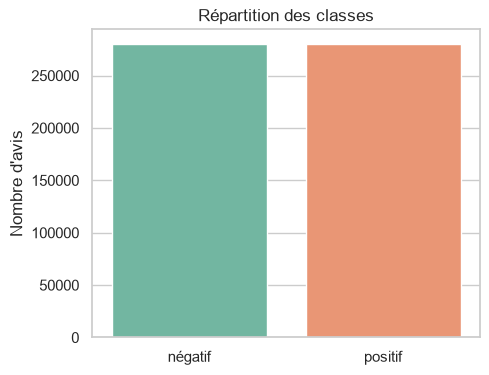

In [76]:
parts = df["label"].value_counts(normalize=True)
print((parts * 100).round(2))
plt.figure(figsize=(5,4))
sns.countplot(data=df, x="label", hue="label", palette="Set2", legend=False)
plt.title("Répartition des classes"); plt.xlabel(""); plt.ylabel("Nombre d'avis"); plt.show()

→ Classes parfaitement équilibrées (50/50), voulu par les auteurs. Pas de rééchantillonnage nécessaire.

## 1.4 Longueur des avis

La longueur (en mots et caractères) aide à choisir la taille de séquence du RNN plus tard (MAXLEN). On regarde aussi si elle diffère entre avis positifs et négatifs.

         n_mots     n_car
count  560000.0  560000.0
mean      133.0     725.9
std       122.6     669.0
min         1.0       1.0
25%        51.0     279.0
50%        97.0     528.0
75%       174.0     946.0
max      1052.0    5273.0


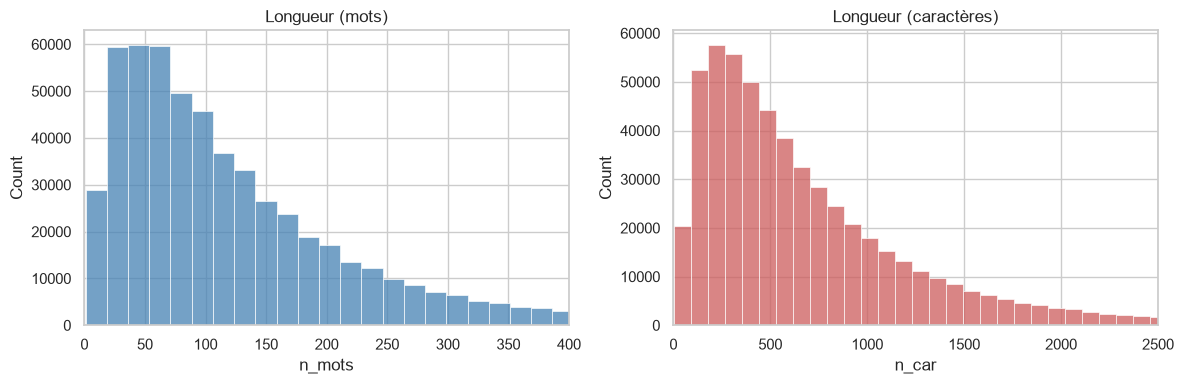

In [77]:
df["n_mots"] = df["review_text"].str.count(r"\S+")
df["n_car"]  = df["review_text"].str.len()
print(df[["n_mots","n_car"]].describe().round(1))

fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.histplot(df["n_mots"], bins=60, ax=ax[0], color="steelblue"); ax[0].set_xlim(0,400); ax[0].set_title("Longueur (mots)")
sns.histplot(df["n_car"],  bins=60, ax=ax[1], color="indianred");  ax[1].set_xlim(0,2500); ax[1].set_title("Longueur (caractères)")
plt.tight_layout(); plt.show()

mediane_mots = df["n_mots"].median()
part_200 = df["n_mots"].le(200).mean()


→ Avis plutôt courts avec une longue traîne. On fixera `MAXLEN=200` pour le RNN.

## 1.5 Mots les plus fréquents (par classe)

Si les mots fréquents diffèrent entre négatif et positif, c'est que le texte porte un signal exploitable pour la classification.

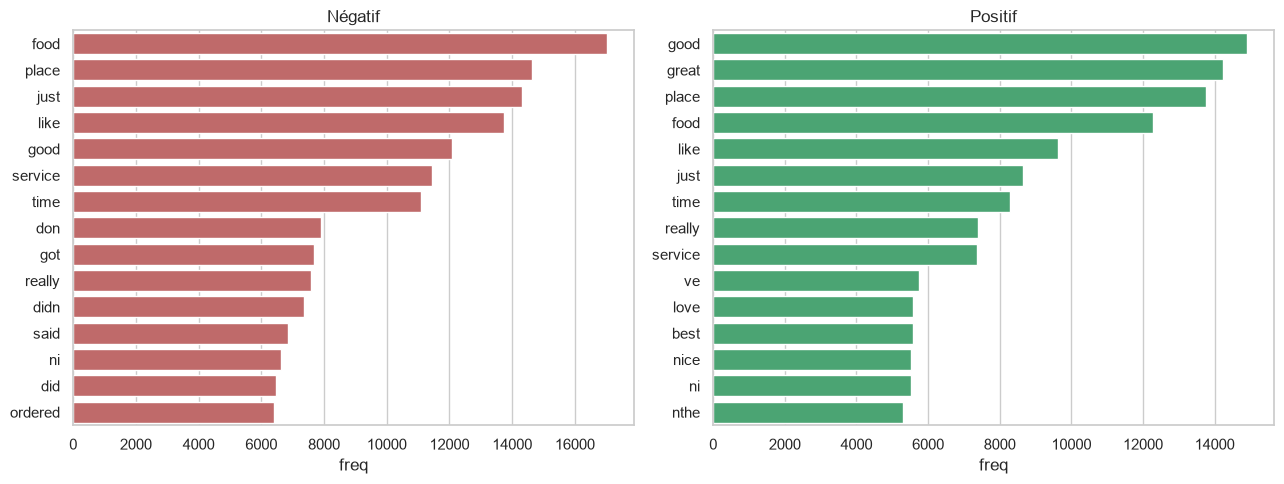

In [78]:
from sklearn.feature_extraction.text import CountVectorizer
sample = df.sample(min(50_000, len(df)), random_state=42)

def top_mots(textes, n=15):
    vec = CountVectorizer(stop_words="english", max_features=5000)
    X = vec.fit_transform(textes)
    freq = np.asarray(X.sum(axis=0)).ravel()
    mots = vec.get_feature_names_out()
    o = freq.argsort()[::-1][:n]
    return pd.DataFrame({"mot": mots[o], "freq": freq[o]})

neg = top_mots(sample[sample.label=="négatif"]["review_text"])
pos = top_mots(sample[sample.label=="positif"]["review_text"])
fig, ax = plt.subplots(1,2, figsize=(13,5))
sns.barplot(data=neg, x="freq", y="mot", ax=ax[0], color="indianred");     ax[0].set_title("Négatif"); ax[0].set_ylabel("")
sns.barplot(data=pos, x="freq", y="mot", ax=ax[1], color="mediumseagreen"); ax[1].set_title("Positif"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()


→ Vocabulaire nettement différent entre classes (`bad`, `rude` vs `great`, `delicious`) : le signal textuel est exploitable.

# Partie 2 : Nettoyage et modèles classiques

On prépare le texte, on le transforme en nombres (vectorisation), puis on entraîne et compare des modèles classiques.

## 2.1 Étude des avis bruts

On regarde le texte avant tout traitement, pour repérer ce qu'il faudra nettoyer.

In [38]:
for t in df["review_text"].head(2):
    print(repr(t[:180]), "\n")

"Unfortunately, the frustration of being Dr. Goldberg's patient is a repeat of the experience I've had with so many other doctors in NYC -- good doctor, terrible staff.  It seems th" 

"Been going to Dr. Goldberg for over 10 years. I think I was one of his 1st patients when he started at MHMG. He's been great over the years and is really all about the big picture." 



On voit des majuscules, de la ponctuation, des `\n` échappés et des guillemets doublés → à nettoyer.

## 2.2 Nettoyage du texte

Un modèle « sac de mots » compte des mots : on enlève donc le bruit (majuscules, ponctuation, chiffres) pour que « Good » et « good! » comptent pareil.

In [39]:
# Nettoyage : on uniformise le texte pour que le modele compte les mots proprement
def nettoyer(txt):
    # minuscule + suppression des retours a la ligne echappes du dataset
    txt = txt.lower().replace("\\n", " ")
    # on ne garde que les lettres : ponctuation et chiffres deviennent des espaces
    txt = re.sub(r"[^a-z\s]", " ", txt)
    return re.sub(r"\s+", " ", txt).strip()

print("AVANT :", df["review_text"].iloc[0][:110])
print("APRÈS :", nettoyer(df["review_text"].iloc[0])[:110])

AVANT : Unfortunately, the frustration of being Dr. Goldberg's patient is a repeat of the experience I've had with so 
APRÈS : unfortunately the frustration of being dr goldberg s patient is a repeat of the experience i ve had with so ma


## 2.3 Tokenisation et stop words

Tokeniser = découper le texte en mots. Les stop words (the, and, is...) sont très fréquents mais peu informatifs ; on les retirera à la vectorisation.

In [40]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
print("Tokens du 1er avis :", nettoyer(df["review_text"].iloc[0]).split()[:15])
print("Nb stop words EN   :", len(ENGLISH_STOP_WORDS))
print("Exemples           :", sorted(ENGLISH_STOP_WORDS)[:20])

Tokens du 1er avis : ['unfortunately', 'the', 'frustration', 'of', 'being', 'dr', 'goldberg', 's', 'patient', 'is', 'a', 'repeat', 'of', 'the', 'experience']
Nb stop words EN   : 318
Exemples           : ['a', 'about', 'above', 'across', 'after', 'afterwards', 'again', 'against', 'all', 'almost', 'alone', 'along', 'already', 'also', 'although', 'always', 'am', 'among', 'amongst', 'amoungst']


## 2.4 Préparation train/test

On passe les labels en 0/1 (0 = négatif, 1 = positif) et on sous-échantillonne le train à 100k pour un temps de calcul raisonnable sur Colab. Le test reste complet (38k).

In [79]:
# train reduit a 100k pour que ca tourne vite sur Colab ; le test reste complet
indices_train = df.sample(min(100_000, len(df)), random_state=42).index
tr = df.loc[indices_train].reset_index(drop=True)
tr["clean"]   = tr["review_text"].apply(nettoyer)
test["clean"] = test["review_text"].apply(nettoyer)
# labels en 0/1 (0 = negatif, 1 = positif)
y_train = (tr["class_index"]==2).astype(int)
y_test  = (test["class_index"]==2).astype(int)
print("OK", tr.shape)

OK (100000, 6)


## 2.5 Bag of Words vs TF-IDF

Deux façons de transformer le texte en nombres :
- Bag of Words : compte chaque mot.
- TF-IDF : pondère ces comptes pour baisser le poids des mots omniprésents.
On prépare les deux pour les comparer.

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer
# BoW = comptage brut des mots ; TF-IDF = comptage pondere (baisse le poids des mots partout)
bow   = CountVectorizer(stop_words="english", max_features=20000)
tfidf = TfidfVectorizer(stop_words="english", max_features=20000)
# fit sur le train uniquement, puis on applique au test
Xb_tr = bow.fit_transform(tr["clean"]);   Xb_te = bow.transform(test["clean"])
Xt_tr = tfidf.fit_transform(tr["clean"]); Xt_te = tfidf.transform(test["clean"])
print("BoW:", Xb_tr.shape, "| TF-IDF:", Xt_tr.shape)

BoW: (100000, 20000) | TF-IDF: (100000, 20000)


## 2.6 Naive Bayes (BoW vs TF-IDF)

Naive Bayes est un modèle simple et rapide, bonne baseline pour le texte. On l'utilise ici pour départager BoW et TF-IDF.

In [43]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
# Naive Bayes sur les deux representations pour voir laquelle est la meilleure
nb_bow   = MultinomialNB().fit(Xb_tr, y_train)
nb_tfidf = MultinomialNB().fit(Xt_tr, y_train)
print("NB + BoW    :", round(accuracy_score(y_test, nb_bow.predict(Xb_te)), 4))
print("NB + TF-IDF :", round(accuracy_score(y_test, nb_tfidf.predict(Xt_te)), 4))

NB + BoW    : 0.8672
NB + TF-IDF : 0.8765


→ On garde TF-IDF pour la suite.

## 2.7 Les 3 modèles sur TF-IDF — test de plusieurs hyperparamètres

Tous sur TF-IDF. On fait varier l'hyperparamètre clé de chaque modèle :
- Naive Bayes : `alpha` (lissage)
- SVM : `C` (tolérance aux erreurs)
- Random Forest : `n_estimators` (nombre d'arbres)

In [44]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score

# On teste plusieurs valeurs d'hyperparametre par modele, tous sur TF-IDF, et on stocke les scores
resultats = []
def evalue(nom, params, clf):
    clf.fit(Xt_tr, y_train)
    pred = clf.predict(Xt_te)
    acc = accuracy_score(y_test, pred)
    resultats.append({"Modèle": nom, "Params": params, "clf": clf,
                      "Accuracy": acc, "F1": f1_score(y_test, pred)})
    print(f"{nom:14s} {params:18s} -> accuracy = {acc:.4f}")

# Naive Bayes - alpha = lissage. alpha petit colle aux donnees, alpha grand lisse davantage
for a in [0.1, 0.5, 1.0]:
    evalue("Naive Bayes", f"alpha={a}", MultinomialNB(alpha=a))
# SVM - C = tolerance aux erreurs. C faible = marge large (plus general), C eleve = colle aux donnees (risque d'overfit)
for C in [0.1, 1.0, 10.0]:
    evalue("SVM", f"C={C}", LinearSVC(C=C))
# Random Forest - n_estimators = nombre d'arbres. Plus d'arbres = souvent mieux mais plus lent
for n in [50, 100]:
    evalue("Random Forest", f"n_estimators={n}",
           RandomForestClassifier(n_estimators=n, n_jobs=-1, random_state=42))

Naive Bayes    alpha=0.1          -> accuracy = 0.8743
Naive Bayes    alpha=0.5          -> accuracy = 0.8760
Naive Bayes    alpha=1.0          -> accuracy = 0.8765
SVM            C=0.1              -> accuracy = 0.9232
SVM            C=1.0              -> accuracy = 0.9198
SVM            C=10.0             -> accuracy = 0.9021
Random Forest  n_estimators=50    -> accuracy = 0.8822
Random Forest  n_estimators=100   -> accuracy = 0.8879


## 2.8 Classement du meilleur au pire

On trie toutes les configs (modèle + hyperparamètre) par F1. Le F1 combine précision et rappel : plus pertinent que l'accuracy seule. Rang 1 = meilleur.

          Modèle            Params  Accuracy      F1
1            SVM             C=0.1    0.9232  0.9232
2            SVM             C=1.0    0.9198  0.9197
3            SVM            C=10.0    0.9021  0.9019
4  Random Forest  n_estimators=100    0.8879  0.8858
5  Random Forest   n_estimators=50    0.8822  0.8796
6    Naive Bayes         alpha=1.0    0.8765  0.8768
7    Naive Bayes         alpha=0.5    0.8760  0.8763
8    Naive Bayes         alpha=0.1    0.8743  0.8746


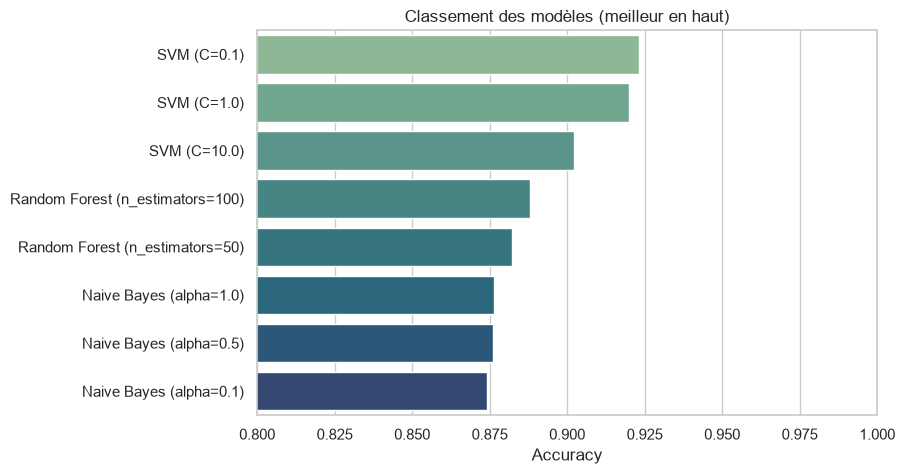

In [80]:
# On classe toutes les configs par F1 (precision + rappel), du meilleur au pire
classement = (pd.DataFrame(resultats)[["Modèle","Params","Accuracy","F1"]]
              .sort_values("F1", ascending=False).reset_index(drop=True))
classement.index = classement.index + 1          # rang 1 = meilleur
print(classement.round(4).to_string())

classement["etiquette"] = classement["Modèle"] + " (" + classement["Params"] + ")"
plt.figure(figsize=(8,5))
sns.barplot(data=classement, x="Accuracy", y="etiquette", hue="etiquette", palette="crest", legend=False)
borne_gauche = max(0, min(0.8, classement["Accuracy"].min() - 0.02))
plt.xlim(borne_gauche, 1.0); plt.ylabel(""); plt.title("Classement des modèles (meilleur en haut)")
plt.show()

## 2.9 Matrices de confusion (meilleure config de chaque modèle)

La matrice de confusion montre où le modèle se trompe : diagonale = bonnes prédictions, hors diagonale = confusions (faux positifs / faux négatifs).

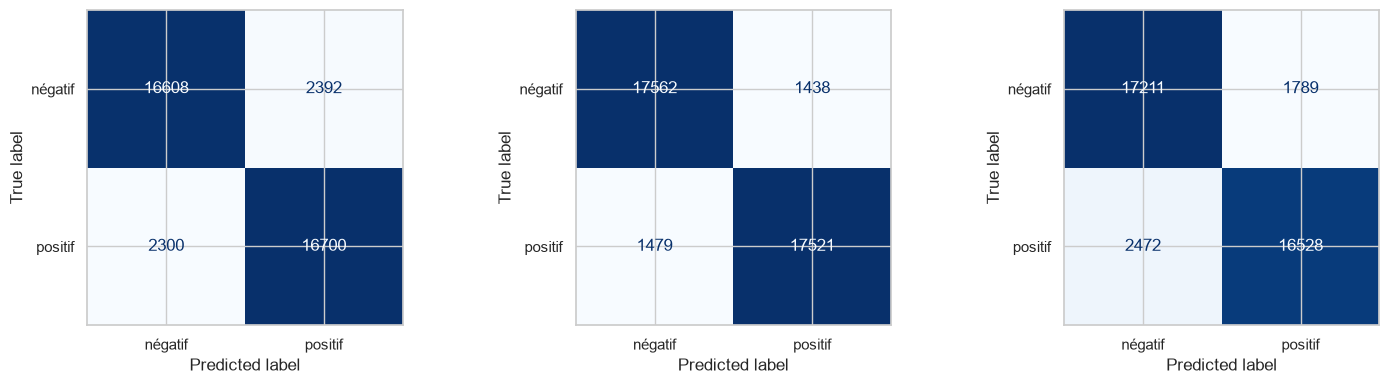

In [82]:
from sklearn.metrics import ConfusionMatrixDisplay
# On garde la meilleure config de chaque modele pour comparer leurs erreurs
best = {}
for r in resultats:
    if r["Modèle"] not in best or r["F1"] > best[r["Modèle"]]["F1"]:
        best[r["Modèle"]] = r

fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a, (nom, r) in zip(ax, best.items()):
    affichage = ConfusionMatrixDisplay.from_predictions(y_test, r["clf"].predict(Xt_te),
        display_labels=["négatif","positif"], cmap="Blues", ax=a, colorbar=False)
    _, faux_positifs, faux_negatifs, _ = affichage.confusion_matrix.ravel()
    
plt.tight_layout(); plt.show()

## 2.10 Étude des erreurs (meilleur modèle classique)

On lit quelques avis mal classés pour comprendre les limites du modèle (souvent sarcasme et négations).

In [47]:
# On prend le meilleur modele puis on lit quelques avis qu'il a mal classes
meilleur = max(resultats, key=lambda r: r["F1"])
print("Meilleur modèle :", meilleur["Modèle"], meilleur["Params"], "| F1 =", round(meilleur["F1"],4), "\n")
pred = meilleur["clf"].predict(Xt_te)
mask = pred != y_test.values
print(f"{mask.sum()} erreurs sur {len(test)} ({mask.mean()*100:.1f}%)\n")
for txt, vr, pr in list(zip(test["review_text"][mask], y_test[mask], pred[mask]))[:3]:
    print(f"[vrai={'pos' if vr else 'neg'} | prédit={'pos' if pr else 'neg'}] {txt[:180]}\n")

Meilleur modèle : SVM C=0.1 | F1 = 0.9232 

2917 erreurs sur 38000 (7.7%)

[vrai=pos | prédit=neg] Contrary to other reviews, I have zero complaints about the service or the prices. I have been getting tire service here for the past 5 years now, and compared to my experience wit

[vrai=neg | prédit=pos] Last summer I had an appointment to get new tires and had to wait a super long time. I also went in this week for them to fix a minor problem with a tire they put on. They \"fixed\

[vrai=pos | prédit=neg] Even when we didn't have a car Filene's Basement was worth the bus trip to the Waterfront. I always find something (usually I find 3-4 things and spend about $60) and better still,



→ Erreurs surtout sur le sarcasme et les négations : un modèle « sac de mots » ignore l'ordre des mots.

# Partie 3 : RNN (LSTM)

Un RNN tient compte de l'ordre des mots : c'est ce qui manquait aux modèles précédents.

## 3.1 Labels + tokenizer

⚠️ Point clé : les labels doivent être 0/1 (0 = négatif, 1 = positif) en `float32`.
Si on laissait 1/2, la perte `binary_crossentropy` donnerait des résultats aberrants.

In [48]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Labels propres (on réutilise y_train / y_test déjà en 0/1 de la partie 2)
ytr = y_train.to_numpy().astype("float32")
yte = y_test.to_numpy().astype("float32")
print("Valeurs des labels :", np.unique(ytr))   # doit afficher [0. 1.]

# Textes déjà nettoyés en partie 2
Xtr_txt, Xte_txt = tr["clean"], test["clean"]

VOCAB, MAXLEN = 20000, 200
# Le tokenizer transforme chaque mot frequent en entier (OOV pour les mots inconnus)
tok = Tokenizer(num_words=VOCAB, oov_token="<OOV>")
tok.fit_on_texts(Xtr_txt)
print("Exemple en entiers :", tok.texts_to_sequences([Xtr_txt.iloc[0]])[0][:12])

Valeurs des labels : [0. 1.]
Exemple en entiers : [16, 34, 12, 44, 9, 14, 306, 6929, 1167, 4, 240, 509]


## 3.2 Séquences et padding

Le réseau attend des séquences de même longueur. Le padding complète les avis courts et coupe les longs à MAXLEN=200.

In [49]:
# Padding : on met tous les avis a la meme longueur (200), on complete ou on coupe
Xtr_seq = pad_sequences(tok.texts_to_sequences(Xtr_txt), maxlen=MAXLEN, padding="post", truncating="post")
Xte_seq = pad_sequences(tok.texts_to_sequences(Xte_txt), maxlen=MAXLEN, padding="post", truncating="post")
print("Forme train :", Xtr_seq.shape, "| test :", Xte_seq.shape)

Forme train : (100000, 200) | test : (38000, 200)


## 3.3 Modèle Embedding + LSTM

- Embedding : transforme chaque mot en vecteur dense appris.
- LSTM : lit la séquence dans l'ordre et en garde une mémoire.
- Dense sigmoïde : sort une probabilité entre 0 (négatif) et 1 (positif).

In [50]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
# Embedding (mot -> vecteur) puis LSTM (lit dans l'ordre) puis sortie sigmoide (proba d'etre positif)
model = Sequential([
    Input(shape=(MAXLEN,), dtype="int32"),
    Embedding(VOCAB, 64),
    LSTM(64), Dropout(0.3),
    Dense(1, activation="sigmoid"),
])
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

## 3.4 Entraînement

epochs = nombre de passages sur les données, batch_size = nombre d'avis traités à la fois, validation_split = part gardée pour surveiller le sur-apprentissage.

In [51]:
# epochs = nombre de passages sur les donnees, 10% garde pour surveiller le sur-apprentissage
hist = model.fit(Xtr_seq, ytr, validation_split=0.1,
                 epochs=1 if MODE_RAPIDE else 3, batch_size=256, verbose=1)

Epoch 1/3
352/352 ━━━━━━━━━━━━━━━━━━━━ 75s 195ms/step - accuracy: 0.5618 - loss: 0.6722 - val_accuracy: 0.5911 - val_loss: 0.6381
Epoch 2/3
352/352 ━━━━━━━━━━━━━━━━━━━━ 66s 188ms/step - accuracy: 0.7643 - loss: 0.4760 - val_accuracy: 0.8932 - val_loss: 0.3029
Epoch 3/3
352/352 ━━━━━━━━━━━━━━━━━━━━ 65s 184ms/step - accuracy: 0.9012 - loss: 0.2882 - val_accuracy: 0.8980 - val_loss: 0.2802


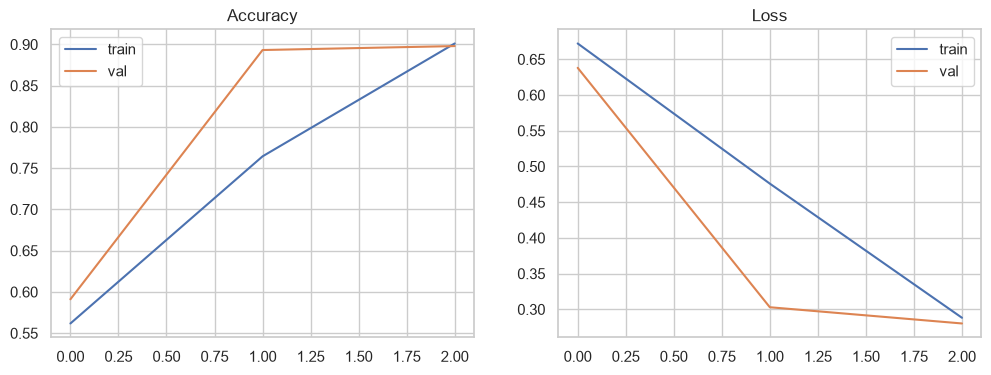

In [83]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].plot(hist.history["accuracy"], label="train"); ax[0].plot(hist.history["val_accuracy"], label="val"); ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(hist.history["loss"], label="train");     ax[1].plot(hist.history["val_loss"], label="val");     ax[1].set_title("Loss"); ax[1].legend()
if len(hist.history["loss"]) == 1:
    for axe in ax:
        for courbe in axe.lines:
            courbe.set_marker("o")
plt.show()


## 3.5 Évaluation sur les mêmes avis de test que les modèles classiques


Accuracy test : 0.9088
              precision    recall  f1-score   support

     négatif       0.91      0.90      0.91     19000
     positif       0.91      0.91      0.91     19000

    accuracy                           0.91     38000
   macro avg       0.91      0.91      0.91     38000
weighted avg       0.91      0.91      0.91     38000



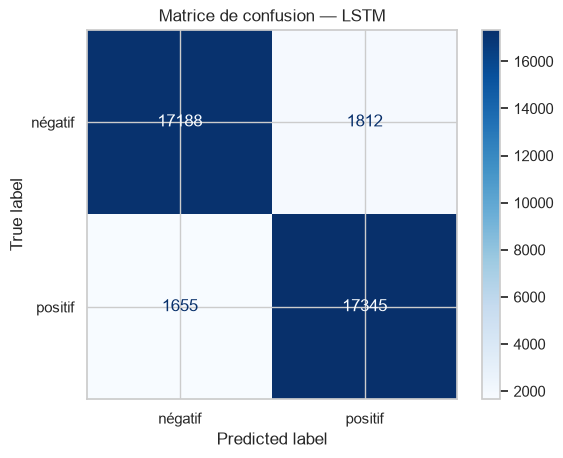

In [84]:
from sklearn.metrics import classification_report
# Evaluation du RNN sur tout le test (38k), comme les modeles classiques, pour une comparaison juste
proba_rnn = model.predict(Xte_seq, verbose=0).ravel()
pred_rnn = (proba_rnn >= 0.5).astype(int)
rnn_acc = accuracy_score(yte, pred_rnn)
rnn_f1  = f1_score(yte, pred_rnn)
print("Accuracy test :", round(rnn_acc, 4))
print(classification_report(yte, pred_rnn, target_names=["négatif","positif"]))
affichage_rnn = ConfusionMatrixDisplay.from_predictions(yte, pred_rnn, display_labels=["négatif","positif"], cmap="Blues")
plt.title("Matrice de confusion — LSTM"); plt.show()


# Partie 4 : Sélection du meilleur modèle

On compare les 4 familles (meilleure config de chacune) sur le même test et on garde le gagnant
pour la WebApp.

In [85]:
# `best` = meilleure config par modèle classique (construit en 2.9)
# On compare la meilleure config de chaque modele classique + le RNN, sur le meme test
compar = [{"Modèle": m, "Params": r["Params"], "Accuracy": r["Accuracy"], "F1": r["F1"]}
          for m, r in best.items()]
compar.append({"Modèle": "RNN", "Params": f"LSTM maxlen={MAXLEN}", "Accuracy": rnn_acc, "F1": rnn_f1})

compar = pd.DataFrame(compar).sort_values("Accuracy", ascending=False).reset_index(drop=True)
compar.index = compar.index + 1
print(compar.round(4).to_string())

# Le mieux classe en accuracy = le modele qu'on garde pour la WebApp
gagnant = compar.iloc[0]["Modèle"]
print("\n>>> Meilleur modèle overall :", gagnant)

          Modèle            Params  Accuracy      F1
1            SVM             C=0.1    0.9232  0.9232
2            RNN   LSTM maxlen=200    0.9088  0.9091
3  Random Forest  n_estimators=100    0.8879  0.8858
4    Naive Bayes         alpha=1.0    0.8765  0.8768

>>> Meilleur modèle overall : SVM


## 4.1 Sauvegarde du modèle gagnant (pour la WebApp)

On sauvegarde le modèle gagnant sur disque pour que la WebApp puisse l'utiliser sans tout ré-entraîner.

In [55]:
import joblib
from sklearn.pipeline import Pipeline

# On sauvegarde seulement le modele gagnant : plus besoin de re-entrainer ensuite
if gagnant == "RNN":
    model.save("rnn_yelp.keras")
    with open("tokenizer.pkl", "wb") as fichier:
        pickle.dump(tok, fichier)
    info_modele = {"type": "rnn", "nom": "RNN (LSTM)", "MAXLEN": MAXLEN}
    fichiers_modele = ["rnn_yelp.keras", "tokenizer.pkl"]
    print("Sauvegardé : modèle RNN")
else:
    # L’application nettoie le texte avant de le transmettre au pipeline.
    clf = best[gagnant]["clf"]
    pipe = Pipeline([("tfidf", tfidf), ("clf", clf)])
    if gagnant == "SVM":
        from sklearn.calibration import CalibratedClassifierCV

        indices_reserve = df.index.difference(indices_train)
        if len(indices_reserve) >= 5000:
            from sklearn.frozen import FrozenEstimator

            # Le SVM et TF-IDF restent figés. Seule la conversion du score en probabilité est apprise.
            calibration = df.loc[indices_reserve, "class_index"].sample(5000, random_state=43)
            textes_calibration = df.loc[calibration.index, "review_text"].map(nettoyer)
            pipe = CalibratedClassifierCV(FrozenEstimator(pipe), method="sigmoid")
            pipe.fit(textes_calibration, calibration.eq(2).astype(int))
        else:
            # En mode rapide, tous les avis chargés servent déjà aux modèles.
            # Chaque pli fournit des scores sur les avis écartés de son entraînement.
            pipe = CalibratedClassifierCV(pipe, method="sigmoid", cv=3, ensemble=False)
            pipe.fit(tr["clean"], y_train)
    joblib.dump(pipe, "model_sklearn.joblib", compress=3)
    info_modele = {"type": "sklearn", "nom": gagnant}
    fichiers_modele = ["model_sklearn.joblib"]
    print("Sauvegardé : pipeline", gagnant)

with open("model_info.pkl", "wb") as fichier:
    pickle.dump(info_modele, fichier)

Sauvegardé : pipeline SVM


# Partie 5 : WebApp Streamlit

`app.py` charge automatiquement le modèle gagnant (RNN ou classique) et prédit le sentiment.

## 5.1 Génération de app.py


In [72]:
%%writefile app.py
import pickle
import re
from pathlib import Path

import streamlit as st


st.set_page_config(page_title="Analyse de sentiment d’un avis", layout="centered")
st.html("""
<style>
    html {font-size: 90%;}
    [data-testid="stMainBlockContainer"] {
        max-width: 52.5rem;
        padding: .85rem 7.5rem 2rem 1rem;
    }
    @media (max-width: 52.5rem) {
        [data-testid="stMainBlockContainer"] {max-width: 46rem; padding-right: 1rem;}
    }
    [data-testid="stAppDeployButton"] {display: none;}
    [data-testid="stHeader"] {background: transparent; pointer-events: none;}
    [data-testid="stToolbar"] {pointer-events: auto;}
    .stButton button[kind="primary"] {
        background-color: #c0404d;
        border-color: #c0404d;
        color: white;
    }
    .stButton button[kind="primary"]:hover {background-color: #a93440;}
    [data-testid="stProgress"] [role="progressbar"] > div > div {background-color: #3282df;}
</style>
""")

st.title("Analyse de sentiment d’un avis")
st.markdown("Collez un avis **en anglais** ou importez un fichier texte pour obtenir sa catégorie.")


def nettoyer(txt):
    txt = txt.lower().replace("\\n", " ")
    txt = re.sub(r"[^a-z\s]", " ", txt)
    return re.sub(r"\s+", " ", txt).strip()


dossier = Path(__file__).resolve().parent
fiche = dossier / "model_info.pkl"
if not fiche.is_file():
    st.error("Modèle introuvable. Exécute la partie 4 du notebook pour le sauvegarder.")
    st.stop()

with fiche.open("rb") as fichier:
    info = pickle.load(fichier)


@st.cache_resource
def charger(type_modele, version_sauvegarde):
    if type_modele == "rnn":
        from tensorflow.keras.models import load_model

        with (dossier / "tokenizer.pkl").open("rb") as fichier:
            tokenizer = pickle.load(fichier)
        return load_model(dossier / "rnn_yelp.keras"), tokenizer

    import joblib
    return joblib.load(dossier / "model_sklearn.joblib"), None


def analyser(avis):
    if info["type"] == "rnn":
        from tensorflow.keras.preprocessing.sequence import pad_sequences

        modele, tokenizer = charger("rnn", fiche.stat().st_mtime_ns)
        sequence = pad_sequences(tokenizer.texts_to_sequences([avis]), maxlen=info["MAXLEN"],
                                 padding="post", truncating="post")
        return float(modele.predict(sequence, verbose=0)[0, 0]), "Probabilité associée", "Probabilités estimées par le LSTM"

    modele, _ = charger("sklearn", (dossier / "model_sklearn.joblib").stat().st_mtime_ns)
    if hasattr(modele, "predict_proba"):
        positif = float(modele.predict_proba([avis])[0, list(modele.classes_).index(1)])
        legende = ("Probabilités calibrées à partir des scores du SVM" if info["nom"] == "SVM"
                   else f"Probabilités estimées par le modèle {info['nom']}")
        return positif, "Probabilité associée", legende

    # Les anciens exports du TP contiennent un LinearSVC sans calibration.
    from scipy.special import expit

    score = float(expit(modele.decision_function([avis])[0]))
    return score, "Score associé", "Scores indicatifs de l’ancien SVM sans calibration"


texte = st.text_area("Votre texte", height=160)
fichier_texte = st.file_uploader("Ou importer un fichier texte", type=["txt"],
                                 )

if st.button("Analyser", type="primary", width="stretch"):
    if fichier_texte is not None:
        donnees = fichier_texte.getvalue()
        encodage = "utf-16" if donnees.startswith((b"\xff\xfe", b"\xfe\xff")) else "utf-8-sig"
        try:
            texte = donnees.decode(encodage)
        except UnicodeDecodeError:
            st.error("Le fichier est illisible. Enregistrez-le au format texte UTF-8 puis réessayez.")
            st.stop()

    avis = nettoyer(texte)
    if not avis:
        st.warning("Saisissez un avis en anglais ou importez un fichier .txt contenant du texte.")
        st.stop()

    positif, libelle, legende = analyser(avis)
    negatif = 1 - positif
    categorie = "Positif" if positif >= 0.5 else "Négatif"
    confiance = max(positif, negatif)

    st.subheader(f"Catégorie : {categorie}")
    st.metric(libelle, f"{confiance:.1%}")
    st.progress(confiance)
    st.caption(legende)
    st.json({"Négatif": f"{negatif:.1%}", "Positif": f"{positif:.1%}"})

Overwriting app.py


In [73]:
# Récupérer l’application et les fichiers du modèle sélectionné
from zipfile import ZipFile

try:
    from google.colab import files as fichiers_colab
except ImportError:
    fichiers_colab = None

fichiers_app = ["app.py", "model_info.pkl", *fichiers_modele]
if fichiers_colab is None:
    print("Application et modèle disponibles dans", Path.cwd())
    print(*fichiers_app, sep="\n")
else:
    with ZipFile("app_yelp.zip", "w") as paquet:
        for nom in fichiers_app:
            paquet.write(nom)
    fichiers_colab.download("app_yelp.zip")

Application et modèle disponibles dans d:\33610\Documents\Repos\IPSSI\TP_RNN\TP_RNN
app.py
model_info.pkl
model_sklearn.joblib


## 5.2 Lancer la WebApp



In [75]:
import atexit
import socket
import subprocess
import sys
import time
from urllib.error import URLError
from urllib.request import urlopen

app_yelp = Path("app.py").resolve()
if "serveur_yelp" not in globals() or serveur_yelp.poll() is not None:
    with socket.socket() as prise:
        prise.bind(("127.0.0.1", 0))
        port_yelp = prise.getsockname()[1]
    serveur_yelp = subprocess.Popen([
        sys.executable, "-m", "streamlit", "run", str(app_yelp),
        "--server.address=127.0.0.1", f"--server.port={port_yelp}",
        "--server.headless=true",
    ])
    atexit.register(serveur_yelp.terminate)
for _ in range(60):
    if serveur_yelp.poll() is not None:
        raise RuntimeError(f"Streamlit s’est arrêté (code {serveur_yelp.returncode}).")
    try:
        with urlopen(f"http://127.0.0.1:{port_yelp}/_stcore/health", timeout=1) as reponse:
            if reponse.status == 200:
                break
    except URLError:
        pass
    time.sleep(1)
else:
    raise TimeoutError("Streamlit ne répond pas. Relance cette cellule.")
if fichiers_colab is None:
    from IPython.display import Markdown, display
    #display(Markdown(f"[Ouvrir l’application Yelp en local](http://127.0.0.1:{port_yelp})"))
    display(Markdown(f"[Ouvrir l’application Yelp webapp link](https://analyse-avis-nelp-uyc9btfp6w9vpbckawpwdj.streamlit.app)"))

else:
    from google.colab import output
    output.serve_kernel_port_as_iframe(port_yelp, height=600)

[Ouvrir l’application Yelp webapp link](https://analyse-avis-nelp-uyc9btfp6w9vpbckawpwdj.streamlit.app)

Pour arrêter Streamlit, exécute `serveur_yelp.terminate()` dans une cellule. On peux aussi relancer le script depuis un terminal où l’environnement du TP est activé avec `python -m streamlit run app.py`. Dans Colab, le ZIP téléchargé contient le script et le modèle.

In [ ]:
#serveur_yelp.terminate()

# Conclusion

- EDA : 560k avis, classes 50/50, pas de manquants, avis courts → `MAXLEN=200`.
- Modèles classiques : TF-IDF ≥ BoW ; classement des configs du meilleur au pire (partie 2.8).
- RNN (LSTM) : labels en 0/1, capte l'ordre des mots (négations) ; évalué sur le même test.
- Sélection : on compare les 4 familles sur le même test et on garde le meilleur overall.
- WebApp : Streamlit charge automatiquement ce modèle gagnant pour prédire de nouveaux avis.